In [1]:
cd ..

/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis


In [2]:
import numpy as np 
import pandas as pd 
import requests
import json
import pytz
from datetime import datetime
from multithread_processing.base_job import BaseJob
from utils.logger_utils import get_logger
from databases.mongodb_main import MongoDBMain



In [3]:
##Filter hot_burn
# with open('data/special_wallets/burn_wallets.json', 'r') as file:
#     burn_data = json.load(file)

# with open('data/special_wallets/hot_wallets.json', 'r') as file:
#     hot_data = json.load(file)

# burn_addresses = []    
# hot_addresses = []    

# for _, burn_value in burn_data.items():
#     burn_addresses.extend(burn_value)
# for _, hot_name in hot_data.items():
#     value_lst = list(hot_name.values())
#     addresses_lst = value_lst[1]
#     for _, hot_address in addresses_lst.items():
#         hot_addresses.extend(hot_address)
# burn_addresses = set(burn_addresses)
# burn_addresses.update(hot_addresses)
# hot_burn_addresses = set(burn_addresses)

In [4]:
class GetTransactionInfo(BaseJob):
    def __init__(self, chain, collections, historical_token_price, wallets_list: list, filename: str, start_date, end_date,
                 max_workers, batch_size):
        
        mongo = MongoDBMain(chain=chain)
        self.transac_collection = mongo._db[collections]        
        self.transaction_info = list()
        self.transfer_info = list()
        self.filename = filename
        self.start_date = start_date
        self.end_date = end_date
        self.historical_token_price = historical_token_price
        super().__init__(work_iterable=wallets_list,
                         max_workers=max_workers,
                         batch_size=batch_size)

    def _execute_batch(self, works):
        df_list = list()
        cursor =self.transac_collection.find({"block_timestamp" : {"$gte": self.start_date, "$lte": self.end_date},'from_address': {'$in': works}},{'from_address':1, 'to_address':1, 'value':1, 'block_timestamp':1,'transaction_type':1})
        for doc in cursor:
            single_transaction_info = dict(doc) 
            if single_transaction_info['value'] == '0':
                continue
            else:
                round_timestamp = (single_transaction_info['block_timestamp']  - single_transaction_info['block_timestamp']  % 86400) *1000
                # round_timestamp = (single_transaction_info['block_timestamp'] // 3600) * 3600000
                single_transaction_info['valueInUSD'] = int(single_transaction_info['value']) * self.historical_token_price['ethereum'][round_timestamp]
                df_list.append(single_transaction_info)    

        df_concat = pd.DataFrame(df_list)
        self.transaction_info.append(df_concat)
        
    def _end(self):
        super()._end()
        df = pd.concat(self.transaction_info, ignore_index=True)
        #return df
        df.to_csv(self.filename, index=False)


In [5]:
def format_prices(prices):
    formatted_prices = {}
    for price in prices:
        timestamp = price[0]
        price_value = price[1]
        formatted_prices[timestamp] = price_value
    return formatted_prices

def get_historical_prices(token_id, days=90, vs_currency='usd'):
    url = f'https://api.coingecko.com/api/v3/coins/{token_id}/market_chart?vs_currency={vs_currency}&days={days}'
    response = requests.get(url)
    if response.status_code == 200:
        data = response.json()
        prices = data.get('prices', [])
        formatted_prices = format_prices(prices)
        prices_dict = {token_id: formatted_prices}
        return prices_dict
    else:
        return None

In [6]:
historical_token_price = get_historical_prices('ethereum')
historical_token_round_price = dict()
historical_token_round_price['ethereum'] = {(timestamp - (timestamp % 86400000)): value for timestamp, value in historical_token_price['ethereum'].items()}


In [9]:
logger = get_logger('User infromation exporter')
input_df = pd.read_json('data/reputation_score/aave_reputation.json')
addresses = input_df.wallet.unique().tolist()[0:5]

In [7]:

job = GetTransactionInfo(chain='ethereum', 
                            collections='transactions', 
                            historical_token_price=historical_token_round_price,
                            wallets_list= addresses, 
                            filename='data/transaction_info/test.csv', 
                            start_date=1701388800, 
                            end_date= 1708992000, 
                            max_workers=4, 
                            batch_size=10)
job.run()


[02-28-2024 15:53:03 +07] [INFO] [BatchWorkExecutor] - Started work. Items to process: 100.


[02-28-2024 15:53:10 +07] [INFO] [BatchWorkExecutor] - 15 items processed. Progress is 15%.
[02-28-2024 15:53:16 +07] [INFO] [BatchWorkExecutor] - 30 items processed. Progress is 30%.
[02-28-2024 15:53:17 +07] [INFO] [BatchWorkExecutor] - 45 items processed. Progress is 45%.
[02-28-2024 15:53:18 +07] [INFO] [BatchWorkExecutor] - 60 items processed. Progress is 60%.
[02-28-2024 15:53:19 +07] [INFO] [BatchWorkExecutor] - 75 items processed. Progress is 75%.
[02-28-2024 15:53:22 +07] [INFO] [BatchWorkExecutor] - 90 items processed. Progress is 90%.
[02-28-2024 15:53:23 +07] [INFO] [BatchWorkExecutor] - 100 items processed. Progress is 100%.
[02-28-2024 15:53:23 +07] [INFO] [BatchWorkExecutor] - Finished work. Total items processed: 100. Took 0:00:20.554740.


## test

In [4]:
import pandas as pd
df = pd.read_csv("/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/transaction_info/test_receiving_groupby.csv")
df

,receiving_wallet,wallet,block_timestamp_tuple,valueInUSD_sum,valueInUSD_median,NumberOfTokensBorrow,NumberOfTokensDeposit,NumberOfTokensHold,totalBorrowInUSD,totalDepositInUSD,totalHoldInUSD,score
0,0x47773580f5de4b2052f94b8b142d71f4efa29f3d,0x3744da57184575064838bbc87a0fc791f5e39ea2,"(1701808127,)",6.062422e+22,6.062422e+22,0,0,1,0.000000e+00,0.000000e+00,2.108893e+07,40468.188820
1,0x545335cafe74b4cea332c6e2c3a557cd93fc8063,0x3744da57184575064838bbc87a0fc791f5e39ea2,"(1706209355,)",6.410310e+15,6.410310e+15,0,0,1,0.000000e+00,0.000000e+00,2.108893e+07,40468.188820
2,0x60ac32d416507c844b43e29b2e12dd23f5277420,0x3744da57184575064838bbc87a0fc791f5e39ea2,"(1705539611,)",4.897518e+22,4.897518e+22,0,0,1,0.000000e+00,0.000000e+00,2.108893e+07,40468.188820
3,0x063ed6f59bd44d8bc99c3b170a3d52b49dcbcfff,0x66a00690bad92cc6bb02d52ae7ed3c2fb671a29a,"(1707782411,)",5.406290e+23,5.406290e+23,0,0,1,0.000000e+00,0.000000e+00,1.929168e+06,21872.378405
4,0x21a31ee1afc51d94c2efccaa2092ad1028285549,0x64b6ebe0a55244f09dfb1e46fe59b74ab94f8be1,"(1702355627,)",1.166985e+24,1.166985e+24,3,2,0,8.499525e+06,6.188003e+07,0.000000e+00,26237.059098
...,...,...,...,...,...,...,...,...,...,...,...,...
4217,0xff9962dcddc7f839d60090740a84467a94352ac4,0x5770815b0c2a09a43c9e5aecb7e2f3886075b605,"(1706803487, 1705829531, 1706519615, 170584463...",2.377352e+21,2.583499e+20,0,0,1,0.000000e+00,0.000000e+00,6.069155e+06,25890.507175
4218,0xff9f7ec6e02bccd4d725b809cbd2410de22c10f1,0x5770815b0c2a09a43c9e5aecb7e2f3886075b605,"(1701430571,)",8.768773e+20,8.768773e+20,0,0,1,0.000000e+00,0.000000e+00,6.069155e+06,25890.507175
4219,0xffaca3564399c2603fcd76295da68e3c654a6fac,0x5770815b0c2a09a43c9e5aecb7e2f3886075b605,"(1706042207,)",1.351217e+22,1.351217e+22,0,0,1,0.000000e+00,0.000000e+00,6.069155e+06,25890.507175
4220,0xffc3884e5028fb279dbefe83dd18329c8fd0419d,0x5770815b0c2a09a43c9e5aecb7e2f3886075b605,"(1703700143,)",1.332791e+21,1.332791e+21,0,0,1,0.000000e+00,0.000000e+00,6.069155e+06,25890.507175


##  Postgres test

In [6]:
blockchain_etl = MongoDBMain(chain='ethereum')

block_timestamp_mappings = blockchain_etl.get_block_number_to_timestamp(start_block=18687851,
                                                                                                      end_block=19129889)

In [22]:
from databases.postgresql import PostgresDB
postgres = PostgresDB()
transfers_data = postgres.query_addresses(addresses=addresses,from_block=18687851,
                                                        to_block=19129889,
                                                        chain_id='0x1')
output_data = []
fields_to_select =['contract_address', 'block_number', 'from_address', 'to_address', 'value']
for row in transfers_data:
    new_row = row[:1] + (block_timestamp_mappings[row[1]],) +row[2:]

    output_data.append(dict(zip(fields_to_select, new_row)))

### Mongo Entity

In [2]:
from databases.mongodb_entity import MongoDBEntity


In [8]:
input_df = pd.read_json('data/reputation_score_27_2/aave_reputation.json')
input_address = input_df.wallet.unique().tolist()[0:5]
addresses = []
for address in input_address:
    addresses.append('0x1_'+address)


In [9]:
addresses

['0x1_0x3744da57184575064838bbc87a0fc791f5e39ea2',
 '0x1_0x5a801a9418d036fd453078c3adcb761fdc5ae695',
 '0x1_0x3555ef98046fac600c0b6529e7018ebeca176398',
 '0x1_0x61b0e6b68184eb0316b1285c4e76a15bfc7cd857',
 '0x1_0x80845058350b8c3df5c3015d8a717d64b3bf9267']

In [14]:
mongo_klg = MongoDBEntity()
mongo_klg_wallet=mongo_klg.wallets
wallets = mongo_klg_wallet.find({'_id': {'$in': addresses}})
wallet_lst = []
for wallet in wallets:
    wallet_lst.append(wallet)
wallet_df = pd.DataFrame(wallet_lst)
wallet_df.columns

Index(['_id', 'address', 'chainId', 'newElite', 'borrowChangeLogs', 'lendings',
       'depositInUSD', 'borrowTokens', 'lastUpdatedAt', 'depositChangeLogs',
       'tokenChangeLogs', 'balanceChangeLogs', 'depositTokens',
       'borrowTokenChangeLogs', 'borrowInUSD', 'tokens', 'balanceInUSD',
       'depositTokenChangeLogs', 'elite', 'dailyNumberOfTransactions',
       'dailyTransactionAmounts', 'numberCallsTopContracts', 'liquidationLogs',
       'numberOfLiquidation', 'totalValueOfLiquidation',
       'dailyAllTransactions', 'flagged', 'newExtend', 'createdAt',
       'frequencyOfDappTransactions', 'numberOfInteractedDapps',
       'typesOfInteractedDapps', 'numberOfReputableDapps', 'tokensInteraction',
       'tags', 'type', 'newTarget', 'lastTokenInteractedAt',
       'lastSyncedDataAt', 'lastSyncedFullDataAt', 'nfts', 'rewards', 'vaults',
       'dexes', 'selective', 'chainName', 'isNew', 'writingLock'],
      dtype='object')

In [1]:
import requests
import time
def format_prices(prices):
    formatted_prices = {}
    for price in prices:
        timestamp = price[0]
        price_value = price[1]
        formatted_prices[timestamp] = price_value
    return formatted_prices

def get_historical_prices(token_id, days=92, vs_currency='usd'):
    url = f'https://api.coingecko.com/api/v3/coins/{token_id}/market_chart?vs_currency={vs_currency}&days={days}'
    response = requests.get(url)
    print(response.status_code)
    if response.status_code == 200:
        time.sleep(3)
    elif response.status_code == 429:
        time.sleep(60)
        response = requests.get(url)
    else:
        return None
    
    data = response.json()
    prices = data.get('prices', [])
    formatted_prices = format_prices(prices)
    prices_dict = {token_id: formatted_prices}
    return prices_dict

In [3]:
get_historical_prices('bnb')

404


In [78]:
aave_from = pd.read_csv("/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/transfer_info/from_transfer.csv")
aave_to = pd.read_csv("/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/transfer_info/to_transfer.csv")


In [ ]:
import json

In [48]:
token_from = aave_from.contract_address.unique().tolist()
token_to = aave_to.contract_address.unique().tolist()
token_from.extend(token_to)
tokens = list(set(token_from))
with open('/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/tokens/aave_tokens.json', "w") as json_file:
    json.dump(tokens, json_file, indent=4)

In [49]:
with open('/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/tokens/aave_tokens.json', "r") as json_file:
    data = json.load(json_file)

In [28]:
historical_token_price = get_historical_prices('airnft-token')
print(historical_token_price)
historical_token_round_price = dict()

historical_token_round_price['airnft-token'] = {(timestamp - (timestamp % 86400000)): value for timestamp, value in historical_token_price['airnft-token'].items()}

429
{'airnft-token': {1701475200000: 0.0012436522456428483, 1701561600000: 0.0012494789766214203, 1701648000000: 0.001249378142686813, 1701734400000: 0.0012575906762466345, 1701820800000: 0.0012410994152013282, 1701907200000: 0.0011410766413160096, 1701993600000: 0.0011718880449486596, 1702080000000: 0.0011990750129799103, 1702166400000: 0.0011982851539001946, 1702252800000: 0.001214548899103537, 1702339200000: 0.0011068480136135431, 1702425600000: 0.0010085863035178386, 1702512000000: 0.0009986413628549464, 1702598400000: 0.0010281176711467292, 1702684800000: 0.0009668426111913278, 1702771200000: 0.0009639195032261808, 1702857600000: 0.0009527960207278551, 1702944000000: 0.0009342008602369286, 1703030400000: 0.0009710455200180209, 1703116800000: 0.0010385634372220562, 1703203200000: 0.001029199910777607, 1703289600000: 0.0010123299825562078, 1703376000000: 0.0010272573947850657, 1703462400000: 0.0009800739430138835, 1703548800000: 0.0009772396451878458, 1703635200000: 0.00109218520260

In [1]:

import plotly.plotly as py
from plotly.graph_objs import *
py.sign_in('username', 'api_key')
trace1 = {
  "uid": "bc205455-f2a3-4d3f-abf3-c40c95a88a07", 
  "type": "bar", 
  "x": [0.00013121034475573932, 0.00014993766193974447, 0.0002585219182364357, 0.0010521100636865248, 0.001284185169798048, 0.001329189790355068, 0.0014440240241685514, 0.0018821589336620167, 0.0022027307162027663, 0.002946483536984531, 0.006552406418814974, 0.007849215937398669, 0.009352968392914428, 0.035643426038373754, 0.0616390968690732, 0.09586633897352569, 0.1085875298538611, 0.6618284653562488], 
  "y": ["cuarto_de_servicio", "cerca_parques", "tiempo_de_construido", "habitaciones", "gimnasio", "knn_50_habitaciones_ratio", "bano_hab_ratio", "knn_area_area_ratio", "knn_50_estrato_ratio", "knn_50_area_ratio", "banos", "con_muebles", "knn_area", "knn_pred_geo", "parqueadero", "estrato", "knn_pred_1", "area"], 
  "orientation": "h"
}
data = Data([trace1])
layout = {
  "title": {"text": "Feature Importance"}, 
  "width": 800, 
  "xaxis": {"title": {"text": "Feature Importance"}}, 
  "yaxis": {
    "title": {
      "font": {"size": 16}, 
      "text": "features"
    }, 
    "tickfont": {"size": 10}
  }, 
  "height": 800, 
  "margin": {"l": 200}, 
  "autosize": False
}
fig = Figure(data=data, layout=layout)
plot_url = py.plot(fig)

ImportError: 
The plotly.plotly module is deprecated,
please install the chart-studio package and use the
chart_studio.plotly module instead. 


In [12]:
len(importances)

20

In [14]:

importances = np.array(['Diff2VecSimi', 'XSentNativeToken','XReceivedNativeToken','SubXSentBUSD-T','SubXSentNativeToken','XSentBUSD-T','XReceivedBUSD-T','SubXReceivedNativeToken','SubXReceivedBUSD-T','SubXSentBUSD','XReceivedBUSD','XSentBUSD','SubXReceivedBUSD', 'XTime11','XTime12','XTime13','XTime14','XTime15','XTime10','XTime9'])

# Get feature names
feature_names = np.array([9054,8501,8342,8213,7500,7401,6500,6402,6250,5902,5801,5602,5580,5575,5570,5565,5560,5555,5550,5545])




# Create a bar chart with the specified color scale
fig = go.Figure(data=go.Bar(
            x=importances,
            y=feature_names,
            orientation='h',
            marker=dict(color=importances),
            hovertemplate='%{x:.2f}',
        ))

fig.update_layout(title='Feature Importance',
                  xaxis_title='Importance',
                  yaxis_title='Features')

fig.show()


ValueError: 
    Invalid element(s) received for the 'color' property of bar.marker
        Invalid elements include: ['Diff2VecSimi', 'XSentNativeToken', 'XReceivedNativeToken', 'SubXSentBUSD-T', 'SubXSentNativeToken', 'XSentBUSD-T', 'XReceivedBUSD-T', 'SubXReceivedNativeToken', 'SubXReceivedBUSD-T', 'SubXSentBUSD']

    The 'color' property is a color and may be specified as:
      - A hex string (e.g. '#ff0000')
      - An rgb/rgba string (e.g. 'rgb(255,0,0)')
      - An hsl/hsla string (e.g. 'hsl(0,100%,50%)')
      - An hsv/hsva string (e.g. 'hsv(0,100%,100%)')
      - A named CSS color:
            aliceblue, antiquewhite, aqua, aquamarine, azure,
            beige, bisque, black, blanchedalmond, blue,
            blueviolet, brown, burlywood, cadetblue,
            chartreuse, chocolate, coral, cornflowerblue,
            cornsilk, crimson, cyan, darkblue, darkcyan,
            darkgoldenrod, darkgray, darkgrey, darkgreen,
            darkkhaki, darkmagenta, darkolivegreen, dark

In [26]:
import plotly.graph_objects as go

# Your category features list
category_features = ['Diff2VecSimi', 'XSentNativeToken','XReceivedNativeToken','SubXSentBUSD-T','SubXSentNativeToken','XSentBUSD-T','XReceivedBUSD-T','SubXReceivedNativeToken','SubXReceivedBUSD-T','SubXSentBUSD','XReceivedBUSD','XSentBUSD','SubXReceivedBUSD', 'XTime11','XTime12','XTime13','XTime14','XTime15','XTime10','XTime9']

# Their corresponding importance scores
importance_scores = [9054,8501,8342,8213,7500,7401,6500,6402,6250,5902,5801,5602,5580,5575,5570,5565,5560,5555,5550,5545]
# category_features.reverse()
# importance_scores.reverse()

# Create a bar trace
trace = go.Bar(
    y=category_features,  # <-- Set y to category features
    x=importance_scores,  # <-- Set x to importance scores
    orientation='h',  # <-- Set orientation to horizontal
    marker=dict(color='blue'),  # Customize the color if needed
)

# Create layout
layout = go.Layout(
    title='Feature Importance',
    yaxis=dict(title='Features'),  # <-- Set y-axis to features
    xaxis=dict(title='Importance Score'),  # <-- Set x-axis to importance score
)

# Create figure
fig = go.Figure(data=[trace], layout=layout)

# Show the plot
fig.show()

In [19]:
import plotly.graph_objects as go

category_features = ['Diff2VecSimi', 'XSentBNB','XReceivedBNB','SubXSentBUSD-T','SubXSentBNB','XSentBUSD-T','XReceivedBUSD-T','SubXReceivedBNB','SubXReceivedBUSD-T','SubXSentBUSD','XReceivedBUSD','XSentBUSD','SubXReceivedBUSD', 'XTime11','XTime12','XTime13','XTime14','XTime15','XTime10','XTime9']
importance_scores = [9254,8251,8142,7913,7500,7401,6500,6402,6250,3902,3801,3602,3580,2850,2780,2720,2660,2605,2550,2505]


category_features.reverse()
importance_scores.reverse()
colorscale = [[0, 'rgb(255,209,162)'], [1, 'rgb(197,121,58)']] 

# Create a bar trace
trace = go.Bar(
    y=category_features,  # <-- Set y to category features
    x=importance_scores,  # <-- Set x to importance scores
    orientation='h',  # <-- Set orientation to horizontal
  marker=dict(color=importance_scores, colorscale=colorscale),  # Customize the color if needed
)

# Create layout
layout = go.Layout(
    height=len(category_features)*30,  # Adjust height based on the number of features
    xaxis=dict(tickfont=dict(size=11))  # <-- Set x-axis to importance score
)



# Create figure
fig = go.Figure(data=[trace], layout=layout)
fig.update_layout(


    yaxis={
        'tickfont': {'size': 11}  # Adjust the size as needed
    }
)

fig.show()# Show the plot
fig.write_image("/Users/nguyenhuyhai/20231/Centic/address-clustering-modeling/BNB_feature_importances.svg")


In [32]:
len(['Diff2VecSimi', 'SubXTimeStd','XTimeStd','SubXTimeMean','XTimeMean','XSentTether','SubXSentTether','XReceivedTether','SubXReceivedTether','XSentUSDC','SubXSentUSDC','XReceivedUSDC','SubXReceivedUSDC', 'XTime11','XTime12','XTime13','XTime14','XTime15','XTime10','XTime9'])

20

In [41]:
import plotly.graph_objects as go

category_features = ['Diff2VecSimi', 'SubXTimeStd','XTimeStd','SubXTimeMean','XTimeMean','XSentTether','SubXSentTether','XReceivedTether','SubXReceivedTether','XSentUSDC','SubXSentUSDC','SubXReceivedUSDC', 'XSentETH','XReceivedUSDC','SubXSentETH','XReceivedETH','SubXReceivedETH','XTime15','XTime10','XTime9']

importance_scores = [9254,8891,8842,7783,7500,7401,6003,5802,5750,3902,3801,3602,3580,3350,2780,2720,2460,2305,2250,2205]

category_features.reverse()
importance_scores.reverse()
colorscale = [[0, 'rgb(255,209,162)'], [1, 'rgb(197,121,58)']] 

# Create a bar trace
trace = go.Bar(
    y=category_features,  # <-- Set y to category features
    x=importance_scores,  # <-- Set x to importance scores
    orientation='h',  # <-- Set orientation to horizontal
  marker=dict(color=importance_scores, colorscale=colorscale),  # Customize the color if needed
)

# Create layout
layout = go.Layout(
    height=len(category_features)*30,  # Adjust height based on the number of features
    xaxis=dict(title=' Mean Decrease in Impurity (MDI)'),  # <-- Set x-axis to importance score
)

fig = go.Figure(data=[trace], layout=layout)

fig.write_image("/Users/nguyenhuyhai/20231/Centic/address-clustering-modeling/ETH_feature_importances.svg")
fig.show()

In [1]:
import pandas as pd
import plotly.graph_objects as go

# Sample DataFrame
data = {
    'SimiScore': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],

    'Hamming': [0.0, 0.2, 0.32, 0.43, 0.54, 0.55, 0.67, 0.71, 0.75, 0.9, 1],
    'Jaro-Winkler':  [0.0, 0.2, 0.32, 0.43, 0.51, 0.65, 0.75, 0.9, 0.92, 0.95, 1],

    'Levenshtein':  [0.0, 0.1, 0.15, 0.33, 0.44, 0.55, 0.6, 0.62, 0.73, 0.85, 1],
    'Jaro':  [0.0, 0.2, 0.37, 0.46, 0.52, 0.57, 0.65, 0.72, 0.82, 0.88, 1],
    'Prefix': [0.0, 0.1, 0.25, 0.3, 0.42, 0.5, 0.57, 0.7, 0.73, 0.85, 1],
    'Post': [0.0, 0.2, 0.22, 0.25, 0.44, 0.55, 0.67, 0.72, 0.78, 0.82, 1]
}

df = pd.DataFrame(data)

# Create the line chart
fig = go.Figure()

for column in df.columns[1:]:  # Exclude the 'Year' column
    fig.add_trace(go.Scatter(x=df['SimiScore'], y=df[column], mode='lines+markers', name=column))

# Update chart layout
fig.update_layout(xaxis_title='Similarity score',
                  yaxis_title='Identical Proportion')

# Show the chart
fig.show()
fig.write_image("/Users/nguyenhuyhai/20231/Centic/address-clustering-modeling/IdenticalProportion.svg")

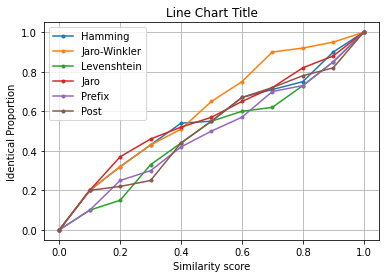

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
# Assuming your dataframe is named 'df' and contains all the necessary data

data = {
    'SimiScore': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],

    'Hamming': [0.0, 0.2, 0.32, 0.43, 0.54, 0.55, 0.67, 0.71, 0.75, 0.9, 1],
    'Jaro-Winkler':  [0.0, 0.2, 0.32, 0.43, 0.51, 0.65, 0.75, 0.9, 0.92, 0.95, 1],

    'Levenshtein':  [0.0, 0.1, 0.15, 0.33, 0.44, 0.55, 0.6, 0.62, 0.73, 0.85, 1],
    'Jaro':  [0.0, 0.2, 0.37, 0.46, 0.52, 0.57, 0.65, 0.72, 0.82, 0.88, 1],
    'Prefix': [0.0, 0.1, 0.25, 0.3, 0.42, 0.5, 0.57, 0.7, 0.73, 0.85, 1],
    'Post': [0.0, 0.2, 0.22, 0.25, 0.44, 0.55, 0.67, 0.72, 0.78, 0.82, 1]
}

df = pd.DataFrame(data)

x_values = df['SimiScore']

# Get the list of column names (excluding the x-axis column)
columns_to_plot = df.columns.tolist()
columns_to_plot.remove('SimiScore')

# Plot each column
for column in columns_to_plot:
    # Get y values for the current column
    y_values = df[column]
    
    # Plot the line chart with data points
    plt.plot(x_values, y_values, marker='.', label=column)

# Adding labels and title
plt.xlabel('Similarity score')
plt.ylabel('Identical Proportion')
plt.title('Line Chart Title')

# Add legend
plt.legend()

# Display the plot
plt.grid(True)  # Add grid lines for better visualization
plt.savefig("/Users/nguyenhuyhai/20231/Centic/address-clustering-modeling/string simi.svg", format='svg')

# Show the plot
plt.show()

In [1]:
cd ..

/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis


In [12]:
from databases.arangodb_klg import ArangoDB

In [13]:
arangodb =ArangoDB()

walletGraphReader
nguyenhuyhai2023
http://34.87.91.182:8529/


In [14]:
addr = arangodb.get_num_send_receive('0x6f98f8293073b8017422d3afa8b35a34f4ebd375')

In [16]:
addr['numberSent']

2

In [7]:

# Define your AQL query with conditions
aql_query = '''
    FOR doc IN ethereum_addresses
    FILTER doc._id == @value && doc.numberSent<= 1000 && doc.numberReceived <=1000
    RETURN doc
'''

bind_vars = {'value': 'ethereum_addresses/0x1_0x6f98f8293073b8017422d3afa8b35a34f4ebd375'}
cursor = arangodb._db.aql.execute(aql_query, bind_vars=bind_vars)




In [8]:
[doc for doc in cursor][0]

{'_key': '0x1_0x6f98f8293073b8017422d3afa8b35a34f4ebd375',
 '_id': 'ethereum_addresses/0x1_0x6f98f8293073b8017422d3afa8b35a34f4ebd375',
 '_rev': '_hgrYM3y--M',
 'chainId': '0x1',
 'address': '0x6f98f8293073b8017422d3afa8b35a34f4ebd375',
 'lastTransferAt': 1707173219,
 'lastUpdatedAt': 1707216032,
 'numberSent': 2,
 'numberReceived': 2}

In [1]:
cd ..

/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis


In [23]:
from pymongo import MongoClient
from databases.mongodb import MongoDB

In [28]:
mongoDb = MongoDB()
cursor = mongoDb._db['available_addresses'].find({},{'address':1})

In [29]:
addresses = []
for cur in cursor[0:10]:
    addresses.append(cur['address'])
addresses

['0xfdc2e337c1c8ffc1e4fee526441ef6c7a447bd81',
 '0xfe55c0ec3642fc79d4eb2c591a0641f187fb0337',
 '0xfed61e31df1f9f56c705acf31e2c05ef05b88e39',
 '0xfd05831e8164de31da2d8df7a77941cf7bebe1f3',
 '0xfe2e023bba664757aaf6b72f9b6a8cfc3ada0b28',
 '0xc382a7af3290a063e0d8c9f281283a4640778b25',
 '0xc9201f9881947f6a2312c5b862d2fff39fadea98',
 '0xdaa7900be57fe8203f18baa27f21480a328c7b0f',
 '0xf8c156320a16965bf4c159c83d5dd1f4194d96ad',
 '0xf175d1a048017248634827cbdd44c8433d50173c']

In [1]:
cd ..

/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis


In [36]:
my_dict = {"key1": 123, "key2": 456}
"key12" not in my_dict

True

In [31]:
from databases.mongodb_main import MongoDBMain

In [33]:
mongooo = MongoDBMain(chain='ethereum')
abcd  = mongooo.get_block_number_to_timestamp(start_block=18809167, end_block=19457983)



KeyboardInterrupt: 

In [14]:
import json
with open('/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/special_wallets/hot_wallets.json', 'r') as file:
    hot_wallets = json.load(file)


In [ ]:
hot_wallets

In [17]:
all_addresses = []

# Iterate over each exchange
for exchange, data in hot_wallets.items():
    # Check if the exchange has "0x1" key in its wallets
    if "0x1" in data["wallets"]:
        # Extend the list with addresses from this exchange's "0x1" wallets
        all_addresses.extend(data["wallets"]["0x1"])

# Print the list of all addresses associated with "0x1"
print(all_addresses)

['...']


In [19]:
len(hot_wallets)

61

In [20]:
hot_wallets

{'binance': {'name': 'Binance',
  'wallets': {'0x1': ['0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be',
    '0xd551234ae421e3bcba99a0da6d736074f22192ff',
    '0x564286362092d8e7936f0549571a803b203aaced',
    '0x0681d8db095565fe8a346fa0277bffde9c0edbbf',
    '0xfe9e8709d3215310075d67e3ed32a380ccf451c8',
    '0x4e9ce36e442e55ecd9025b9a6e0d88485d628a67',
    '0xbe0eb53f46cd790cd13851d5eff43d12404d33e8',
    '0xf977814e90da44bfa03b6295a0616a897441acec',
    '0x001866ae5b3de6caa5a51543fd9fb64f524f5478',
    '0x85b931a32a0725be14285b66f1a22178c672d69b',
    '0x708396f17127c42383e3b9014072679b2f60b82f',
    '0xe0f0cfde7ee664943906f17f7f14342e76a5cec7',
    '0x8f22f2063d253846b53609231ed80fa571bc0c8f',
    '0x28c6c06298d514db089934071355e5743bf21d60',
    '0x21a31ee1afc51d94c2efccaa2092ad1028285549',
    '0xdfd5293d8e347dfe59e90efd55b2956a1343963d',
    '0x56eddb7aa87536c09ccc2793473599fd21a8b17f',
    '0x9696f59e4d72e237be84ffd425dcad154bf96976',
    '0x4d9ff50ef4da947364bb9650892b2554e7be5e2b',


In [11]:
pwd

'/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/notebook'

In [12]:
cd ..

/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis


In [43]:
from services.get_history_price_service import get_historical_prices
eth_price = get_historical_prices('ethereum', days = 98)

In [44]:
import json
import pandas as pd

with open('data/searching_info_18_3/aave_tokens.json','r') as file:
    token_history = json.load(file)

In [45]:
token_history.update(eth_price)

In [ ]:
with open('data/testing_data_18_3/aave_tokens.json','w') as file:
    json.dump(token_history, file, indent=4)

In [32]:
import json
import pandas as pd

with open('data/testing_data_18_3/aave_tokens.json','r') as file:
    token_history = json.load(file)

In [33]:
token_history['0xe8b1e79d937c648ce1fe96e6739ddb2714058a18']

{'1708041600000': 0.002718459110551145,
 '1708128000000': 0.002718459110551145,
 '1708214400000': 0.003051303344655123,
 '1708300800000': 0.004131823814089091,
 '1708387200000': 0.0031769792657106244,
 '1708473600000': 0.0030995535954924784,
 '1708560000000': 0.0025970106497397484,
 '1708646400000': 0.0020615100277411526,
 '1708732800000': 0.002255593080414409,
 '1708819200000': 0.0022047055765227613,
 '1708905600000': 0.0022639422223407362,
 '1708992000000': 0.005071036139478395,
 '1709078400000': 0.005642991015168899,
 '1709164800000': 0.006579226717411877,
 '1709251200000': 0.004059287737622704,
 '1709337600000': 0.004720547949641796,
 '1709424000000': 0.003089270196784594}

In [25]:
import json 
with open('/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/block_timestamp_mapping.json','r') as file:
    dataa = json.load(file)



In [19]:
dataa['19144139']

1706918411

In [20]:
import json 
with open('/Users/nguyenhuyhai/20232/Centic/RecSys/reputation-analysis/data/testing_data_18_3/aave_tokens.json','r') as file:
    dataa = json.load(file)



In [31]:
dataa['0xe8b1e79d937c648ce1fe96e6739ddb2714058a18']

KeyError: '0xe8b1e79d937c648ce1fe96e6739ddb2714058a18'

In [28]:
dataa['19165500']

1707177731

In [34]:
data = {'wallet': ['A', 'A', 'A', 'B','B'],
        'interactedWallet': ['a1', 'a1', 'a2', 'b1','b2'],
        'contract_address': ['a11', 'a12', 'a13', 'b12','b13'],
        'timestampHistory': [[1,2,3], [5,6], [1,5,7], [2],[4,5]],
        'valueInUSDHistorry': [[11,44,55], [24,33], [21,45,53], [10],[11,12]],
}

result_list = []

for index, row in pd.DataFrame(data).iterrows():
    entry = {'wallet': row['wallet']}
    interacted_wallets = {}
    contract_address_dict = {}
    for interacted_wallet, contract_address, timestamp_history, value_history in zip(row['interactedWallet'], row['contract_address'], row['timestampHistory'], row['valueInUSDHistorry']):
        if interacted_wallet not in interacted_wallets:
            interacted_wallets[interacted_wallet] = {}
        if contract_address not in interacted_wallets[interacted_wallet]:
            interacted_wallets[interacted_wallet][contract_address] = {'time': timestamp_history, 'valueInUSDHistory': value_history}
        else:
            print("Error: Duplicate interactedWallet and contract_address pair detected.")

    entry['interactedWallet'] = interacted_wallets
    result_list.append(entry)

print(result_list)


[{'wallet': 'A', 'interactedWallet': {'a': {'a': {'time': 1, 'valueInUSDHistory': 11}}, '1': {'1': {'time': 2, 'valueInUSDHistory': 44}}}}, {'wallet': 'A', 'interactedWallet': {'a': {'a': {'time': 5, 'valueInUSDHistory': 24}}, '1': {'1': {'time': 6, 'valueInUSDHistory': 33}}}}, {'wallet': 'A', 'interactedWallet': {'a': {'a': {'time': 1, 'valueInUSDHistory': 21}}, '2': {'1': {'time': 5, 'valueInUSDHistory': 45}}}}, {'wallet': 'B', 'interactedWallet': {'b': {'b': {'time': 2, 'valueInUSDHistory': 10}}}}, {'wallet': 'B', 'interactedWallet': {'b': {'b': {'time': 4, 'valueInUSDHistory': 11}}, '2': {'1': {'time': 5, 'valueInUSDHistory': 12}}}}]


In [40]:
import pandas as pd

data = {'wallet': ['A', 'A', 'A', 'B', 'B'],
        'interactedWallet': ['a1', 'a1', 'a2', 'b1', 'b2'],
        'contract_address': ['a11', 'a12', 'a13', 'b12', 'b13'],
        'timestampHistory': [[1, 2, 3], [5, 6], [1, 5, 7], [2], [4, 5]],
        'valueInUSDHistorry': [[11, 44, 55], [24, 33], [21, 45, 53], [10], [11, 12]],
}

df = pd.DataFrame(data)

def create_entry(group):
    interacted_wallets = {}
    for _, row in group.iterrows():
        contract_dict = {}
        for ts, val in zip(row['timestampHistory'], row['valueInUSDHistorry']):
            contract_dict[row['contract_address']] = {'time': ts, 'valueInUSDHistory': val}
        interacted_wallets[row['interactedWallet']] = contract_dict
    return {'wallet': group['wallet'].iloc[0], 'interactedWallet': interacted_wallets}

result = df.groupby('wallet').apply(create_entry).tolist()
print(result)



[{'wallet': 'A', 'interactedWallet': {'a1': {'a12': {'time': 6, 'valueInUSDHistory': 33}}, 'a2': {'a13': {'time': 7, 'valueInUSDHistory': 53}}}}, {'wallet': 'B', 'interactedWallet': {'b1': {'b12': {'time': 2, 'valueInUSDHistory': 10}}, 'b2': {'b13': {'time': 5, 'valueInUSDHistory': 12}}}}]


In [58]:
dataa = {
    'wallet': ['A', 'A', 'A', 'B', 'B'],
    'interactedWallet': ['a1', 'a1', 'a2', 'b1', 'b2'],
    'contract_address': ['a11', 'a12', 'a13', 'b12', 'b13'],
    'timestampHistory': [[1, 2, 3], [5, 6], [1, 5, 7], [2], [4, 5]],
    'valueInUSDHistorry': [[11, 44, 55], [24, 33], [21, 45, 53], [10], [11, 12]],
}

result = []
for _, row in pd.DataFrame(dataa).iterrows():
    wallet_dict = {'wallet': row['wallet'], 'interactedWallet': {}}
    interacted_wallet = row['interactedWallet']
    contract_address = row['contract_address']
    timestamps = row['timestampHistory']
    values = row['valueInUSDHistorry']
    
    wallet_dict['interactedWallet'].setdefault(interacted_wallet, {'contract_address': {}})
    wallet_dict['interactedWallet'][interacted_wallet]['contract_address'][contract_address] = {
        'time': timestamps,
        'valueInUSDHistory': values
    }
    result.append(wallet_dict)

print(result)


[{'wallet': 'A', 'interactedWallet': {'a1': {'contract_address': {'a11': {'time': [1, 2, 3], 'valueInUSDHistory': [11, 44, 55]}}}}}, {'wallet': 'A', 'interactedWallet': {'a1': {'contract_address': {'a12': {'time': [5, 6], 'valueInUSDHistory': [24, 33]}}}}}, {'wallet': 'A', 'interactedWallet': {'a2': {'contract_address': {'a13': {'time': [1, 5, 7], 'valueInUSDHistory': [21, 45, 53]}}}}}, {'wallet': 'B', 'interactedWallet': {'b1': {'contract_address': {'b12': {'time': [2], 'valueInUSDHistory': [10]}}}}}, {'wallet': 'B', 'interactedWallet': {'b2': {'contract_address': {'b13': {'time': [4, 5], 'valueInUSDHistory': [11, 12]}}}}}]


In [59]:
data = pd.DataFrame(dataa)

In [47]:
result = [
    {
        'wallet': wallet,
        'interactedWallet': {
            interacted_wallet: {
                'contract_address': {
                    contract_address: {
                        'time': timestamps,
                        'valueInUSDHistory': values
                    }
                }
            }
        }
    }
    for wallet, interacted_wallet, contract_address, timestamps, values in zip(
        dataa['wallet'],
        dataa['interactedWallet'],
        dataa['contract_address'],
        dataa['timestampHistory'],
        dataa['valueInUSDHistorry']
    )
]

In [68]:
data = {
    'wallet': ['A', 'A', 'A', 'B', 'B'],
    'interactedWallet': ['a1', 'a1', 'a2', 'b1', 'b2'],
    'contract_address': ['a11', 'a12', 'a13', 'b12', 'b13'],
    'timestampHistory': [[1, 2, 3], [5, 6], [1, 5, 7], [2], [4, 5]],
    'valueInUSDHistorry': [[11, 44, 55], [24, 33], [21, 45, 53], [10], [11, 12]],
}

def update_format(data):
    result = {}
    for wallet, interacted_wallet, contract_address, timestamp_history, value_history in zip(
        data['wallet'],
        data['interactedWallet'],
        data['contract_address'],
        data['timestampHistory'],
        data['valueInUSDHistorry'],
    ):
        if wallet not in result:
            result[wallet] = {'interactedWallet': {}}
        if interacted_wallet not in result[wallet]['interactedWallet']:
            result[wallet]['interactedWallet'][interacted_wallet] = {'contract_address': {}}
        if contract_address not in result[wallet]['interactedWallet'][interacted_wallet]['contract_address']:
            result[wallet]['interactedWallet'][interacted_wallet]['contract_address'][contract_address] = {
                'time': timestamp_history,
                'valueInUSDHistory': value_history,
            }

    final_result = [{'wallet': wallet, **data} for wallet, data in result.items()]
    return final_result


In [71]:
df = pd.DataFrame(data)

In [72]:
df.to_dict(orient='records')

[{'wallet': 'A',
  'interactedWallet': 'a1',
  'contract_address': 'a11',
  'timestampHistory': [1, 2, 3],
  'valueInUSDHistorry': [11, 44, 55]},
 {'wallet': 'A',
  'interactedWallet': 'a1',
  'contract_address': 'a12',
  'timestampHistory': [5, 6],
  'valueInUSDHistorry': [24, 33]},
 {'wallet': 'A',
  'interactedWallet': 'a2',
  'contract_address': 'a13',
  'timestampHistory': [1, 5, 7],
  'valueInUSDHistorry': [21, 45, 53]},
 {'wallet': 'B',
  'interactedWallet': 'b1',
  'contract_address': 'b12',
  'timestampHistory': [2],
  'valueInUSDHistorry': [10]},
 {'wallet': 'B',
  'interactedWallet': 'b2',
  'contract_address': 'b13',
  'timestampHistory': [4, 5],
  'valueInUSDHistorry': [11, 12]}]